# Phase 6 — Model Evaluation & Selection for FD001
**Notebook:** `04b_Evaluation_FD001.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

### What this notebook does — in this exact order
| Step | Uses | Purpose |
|---|---|---|
| 1. Reload all 4 saved models from Drive | `models/FD001/*` | Prove the saved bundles reproduce Phase 5 predictions |
| 2. Fair CPU timing | validation points | Deployment runs on CPU, so every model is timed on CPU |
| 3. Diagnostic plots | validation points | Actual vs predicted, residuals, error by RUL band, error vs true RUL |
| 4. **Select & freeze** the production model | validation metrics only | Rule is stated and saved **before** the test set is opened |
| 5. **Official NASA test evaluation — once** | `test_FD001.txt` + `RUL_FD001.txt` | Unbiased estimate of real performance |

**Why the order matters:** if we looked at test results and then picked the model, the test set would silently become a second validation set and our reported score would be optimistic. Freezing the choice in a file first makes that impossible to do by accident.

**Conventions (unchanged):** error `d = predicted − true` (d > 0 = **late** = dangerous). NASA score penalises late errors more (`e^{d/10}−1`) than early ones (`e^{−d/13}−1`). Validation metrics use the 200 test-like points; primary metric = RMSE where true RUL ≤ 125. On the official test set, MAE/RMSE/NASA are reported over **all 100 engines** against the **true (uncapped)** RUL, which is the standard convention.



## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:                                   # running locally
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD001", 42
SRC_DIR    = PROJECT_DIR / "src"
MODEL_DIR  = PROJECT_DIR / "models" / FD
PROC_DIR   = PROJECT_DIR / "data" / "processed" / FD
FIG_DIR    = PROJECT_DIR / "reports" / "figures" / FD
RESULT_DIR = PROJECT_DIR / "reports" / "model_results" / FD
sys.path.insert(0, str(PROJECT_DIR))
sns.set_theme(style="whitegrid")

MODELS = ["Linear Regression", "Random Forest", "XGBoost", "LSTM"]
for folder in ["linear_regression", "random_forest", "xgboost", "lstm"]:
    assert (MODEL_DIR / folder / "metadata.json").exists(), f"{folder} missing → run Phase 5 (04_Model_Training_FD001) first"
assert (RESULT_DIR / "validation_comparison.csv").exists(), "Phase 5 results missing"
print("✅ Phase 5 models + results found")

Mounted at /content/drive
✅ Phase 5 models + results found


## Cell 2 — Write `src/prediction.py`
**Why this file exists:** this is the single "raw sensor history → RUL" path. Phase 6 uses it for the test set, and the FastAPI backend will use the **same class** for user uploads, so evaluation measures exactly what the app will run.

`RULPredictor(dataset_dir, model_name)` loads from disk:
1. the model's `metadata.json` (input type, cap, files),
2. the saved preprocessing (`scaler.joblib` + feature order),
3. the feature recipe (`feature_config.json`: window 30 + cycle, or LSTM 30×14),
4. the model itself (joblib / XGBoost JSON / PyTorch state dict).

`predict_last(raw_df)` predicts at each engine's **last observed cycle** — exactly the official test question. The LSTM refuses engines with fewer than 30 cycles instead of inventing padding.

In [2]:
%%writefile {SRC_DIR}/prediction.py
"""
prediction.py â€” Load a saved model bundle and predict RUL from RAW engine history.

Why this file exists: evaluation (Phase 6), the FastAPI backend and the tests must all
turn raw sensor rows into a prediction in exactly the same way:
    raw rows -> saved preprocessing (validate + scale) -> saved feature recipe -> saved model
Everything is read from disk (models/<FD>/...), nothing is re-fitted.
"""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from src import feature_engineering as fe
from src.preprocessing import CMAPSSPreprocessor

MODEL_FOLDERS = {"Linear Regression": "linear_regression", "Random Forest": "random_forest",
                 "XGBoost": "xgboost", "LSTM": "lstm"}


class RULPredictor:
    """One trained model + its preprocessing + its feature recipe, loaded from models/<FD>/."""

    def __init__(self, dataset_dir, model_name: str, device: str = "cpu"):
        dataset_dir = Path(dataset_dir)
        self.name = model_name
        self.dir = dataset_dir / MODEL_FOLDERS[model_name]
        self.meta = json.loads((self.dir / "metadata.json").read_text())
        self.prep = CMAPSSPreprocessor.load(dataset_dir / "preprocessing")
        self.feat_cfg = json.loads((dataset_dir / "feature_config.json").read_text())
        self.cap = float(self.meta["rul_cap"])
        self.device = device
        self.base = self.feat_cfg["base_features"]
        if self.meta["input"] == "sequence":
            from src.model_training import load_lstm
            self.model, _ = load_lstm(self.dir, device)
            self.seq_len = int(self.meta["seq_len"])
            self.min_history = self.seq_len
        else:
            if self.meta["model_file"].endswith(".json"):          # XGBoost
                from xgboost import XGBRegressor
                self.model = XGBRegressor()
                self.model.load_model(self.dir / self.meta["model_file"])
                self.model.set_params(device=device)
                self.model.get_booster().set_param({"device": device})
            else:                                                   # scikit-learn
                self.model = joblib.load(self.dir / self.meta["model_file"])
            tab = self.feat_cfg["tabular"]
            self.window, self.include_cycle = tab["window"], tab["include_cycle"]
            self.feature_order = tab["feature_order"]
            self.min_history = 1

    # -------------------------------------------------------------- core
    def model_inputs(self, raw_df: pd.DataFrame, points: pd.DataFrame):
        """Raw history -> model-ready inputs for each (engine_id, cut_cycle) in `points`."""
        scaled = self.prep.transform(raw_df)                       # validates columns / NaN, then scales
        if self.meta["input"] == "sequence":
            return fe.sequences_at(scaled, self.base, self.seq_len, points)
        feats, _ = fe.build_tabular(scaled, self.base, self.window, self.include_cycle)
        return fe.rows_at(feats, points)[self.feature_order]

    def predict_inputs(self, X) -> np.ndarray:
        """Model-ready inputs -> RUL predictions (clipped at 0)."""
        if self.meta["input"] == "sequence":
            from src.model_training import lstm_predict
            return lstm_predict(self.model, X, self.cap, self.device)
        return np.clip(self.model.predict(X), 0, None)

    def predict_at(self, raw_df: pd.DataFrame, points: pd.DataFrame) -> np.ndarray:
        return self.predict_inputs(self.model_inputs(raw_df, points))

    def predict_last(self, raw_df: pd.DataFrame) -> pd.DataFrame:
        """Predict at each engine's LAST observed cycle (what the official test set asks for)."""
        last = raw_df.groupby("engine_id")["cycle"].max().rename("cut_cycle").reset_index()
        short = last[last["cut_cycle"] < self.min_history]
        if len(short):
            raise ValueError(f"{self.name} needs >= {self.min_history} cycles; engines too short: "
                             f"{short.engine_id.tolist()}")
        last["predicted_rul"] = self.predict_at(raw_df, last)
        return last

Writing /content/drive/MyDrive/Predictive_Maintenance_RUL/src/prediction.py


## Cell 3 — Reload every model from disk and reproduce Phase 5
All models run on **CPU** here. Tree models should reproduce Phase 5 predictions essentially exactly. If Phase 5 ran XGBoost/LSTM on a GPU, CPU predictions can differ by a tiny amount (floating-point differences) — the check below allows for that.

In [3]:
# Cell 3 — Load predictors and validation data
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.model_training as mt, src.prediction as pr
for m in (dl, pp, ev, fe, mt, pr):
    importlib.reload(m)

split    = json.loads((PROC_DIR / "split.json").read_text())
val_cuts = pd.read_csv(PROC_DIR / "val_cut_points.csv")
p5_preds = pd.read_csv(RESULT_DIR / "validation_predictions.csv")
p5_table = pd.read_csv(RESULT_DIR / "validation_comparison.csv", index_col="Model")

d = dl.load_dataset(FD, RAW_DIR)
raw_val = d["train"][d["train"].engine_id.isin(split["val_engine_ids"])]      # raw rows, no labels needed
y_val = val_cuts["true_rul"].values

predictors = {name: pr.RULPredictor(MODEL_DIR, name, device="cpu") for name in MODELS}
CAP = predictors["XGBoost"].cap

val_pred, check = {}, []
for name, p in predictors.items():
    val_pred[name] = p.predict_at(raw_val, val_cuts)
    diff = np.abs(val_pred[name] - p5_preds[name].values).max()
    check.append({"Model": name, "max |CPU − Phase 5| (cycles)": round(float(diff), 4)})
display(pd.DataFrame(check).set_index("Model"))
assert all(c["max |CPU − Phase 5| (cycles)"] < 1.0 for c in check), "Saved model does not reproduce Phase 5!"
print("✅ All 4 saved models reload from disk and reproduce their Phase 5 validation predictions")

,max |CPU − Phase 5| (cycles)
Model,
Linear Regression,0.0000
Random Forest,0.0000
XGBoost,0.0001
LSTM,0.0004


✅ All 4 saved models reload from disk and reproduce their Phase 5 validation predictions


## Cell 4 — Validation table with fair CPU timing
Two timings per model, both on CPU, median of several runs:
- **Model-only inference**: features already prepared → time for the model to score 200 points.
- **End-to-end**: raw sensor rows → validation → scaling → features/sequences → prediction for all 200 points. This is closer to what one API request costs.

Training and tuning times are carried over from Phase 5 (they were measured on Colab, LSTM/XGBoost on GPU).

In [4]:
# Cell 4 — Metrics + CPU timing + model size
rows = []
for name, p in predictors.items():
    X = p.model_inputs(raw_val, val_cuts)
    _, t_model = mt.time_inference(lambda: p.predict_inputs(X), n_repeats=7)
    _, t_e2e = mt.time_inference(lambda: p.predict_at(raw_val, val_cuts), n_repeats=3)
    size_mb = sum(f.stat().st_size for f in p.dir.iterdir() if f.name != "tuning_best_checkpoint.pt") / 1e6
    m = mt.point_metrics(y_val, val_pred[name], CAP)
    rows.append({"Model": name, "MAE (≤125)": m["MAE_le_cap"], "RMSE (≤125)": m["RMSE_le_cap"],
                 "NASA (≤125)": m["NASA_le_cap"], "Bias (≤125)": m["bias_le_cap"], "RMSE (all 200)": m["RMSE_all"],
                 "Train time (s)": p5_table.loc[name, "Train time (s)"],
                 "Tuning time (s)": p5_table.loc[name, "Tuning time (s)"],
                 "CPU inference, model only (ms/200)": t_model * 1000,
                 "CPU end-to-end (ms/200)": t_e2e * 1000, "Model size (MB)": size_mb})
val_table = pd.DataFrame(rows).set_index("Model")
val_table.to_csv(RESULT_DIR / "validation_comparison_cpu.csv")
display(val_table.round(2))

,MAE (≤125),RMSE (≤125),NASA (≤125),Bias (≤125),RMSE (all 200),Train time (s),Tuning time (s),"CPU inference, model only (ms/200)",CPU end-to-end (ms/200),Model size (MB)
Model,,,,,,,,,,
Linear Regression,16.62,20.26,1250.63,6.43,41.86,0.09,0.00,1.49,248.69,0.00
Random Forest,10.87,13.99,481.61,4.27,37.83,39.42,265.23,57.57,410.03,11.57
XGBoost,10.42,13.67,451.26,3.99,37.73,0.48,5.27,8.79,891.05,0.63
LSTM,11.68,15.95,1003.05,3.90,39.66,2.31,23.41,116.60,223.82,0.84


**How to read the timings:** end-to-end time is dominated by preprocessing and feature engineering (rolling windows for 20 engines), not by the model. All four models answer in well under a second, so for an interactive dashboard speed is **not** a deciding factor here — accuracy and safety (late bias / NASA) are.

---
## Cell 5 — Diagnostic plots on validation
Four views, all on the 200 validation points:
1. **Actual vs predicted** — perfect predictions lie on the diagonal. Points above the diagonal are **late** (dangerous).
2. **Residual distribution** — histogram of `d = predicted − true` for points with true RUL ≤ 125. Centred at 0 and narrow is good; a right shift means systematic lateness.
3. **Error by RUL band** — where in an engine's life each model is accurate.
4. **Prediction error vs true RUL** — shows *how* errors change as failure approaches.

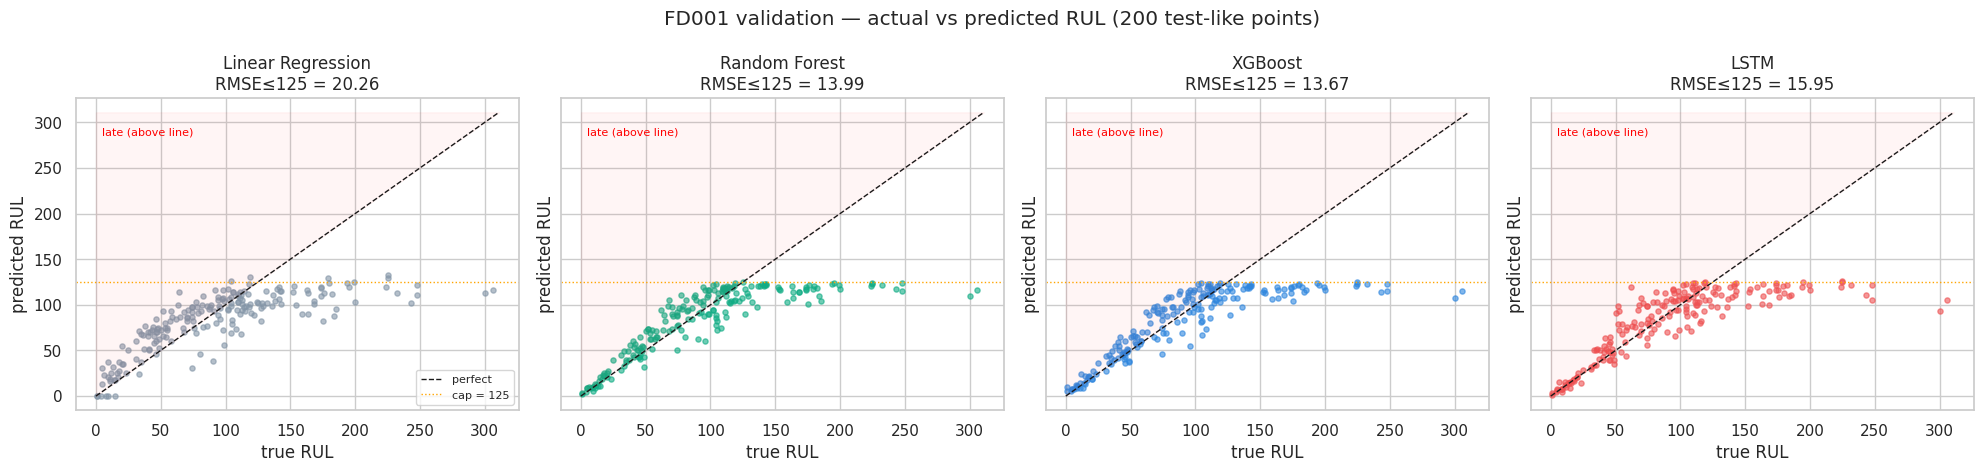

In [5]:
# Cell 5a — Actual vs predicted
colors = {"Linear Regression": "#8395a7", "Random Forest": "#10ac84", "XGBoost": "#2e86de", "LSTM": "#ee5253"}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True, sharey=True)
for ax, name in zip(axes, MODELS):
    ax.scatter(y_val, val_pred[name], s=14, alpha=0.6, color=colors[name])
    lim = max(y_val.max(), 1) + 5
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect")
    ax.axhline(CAP, color="orange", ls=":", lw=1, label=f"cap = {CAP:.0f}")
    ax.fill_between([0, lim], [0, lim], [lim, lim], color="red", alpha=0.04)
    ax.set(title=f"{name}\nRMSE≤125 = {val_table.loc[name, 'RMSE (≤125)']:.2f}", xlabel="true RUL", ylabel="predicted RUL")
    ax.text(5, lim * 0.92, "late (above line)", color="red", fontsize=8)
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("FD001 validation — actual vs predicted RUL (200 test-like points)")
fig.tight_layout(); fig.savefig(FIG_DIR / "17_actual_vs_predicted_val.png", dpi=150, bbox_inches="tight"); plt.show()

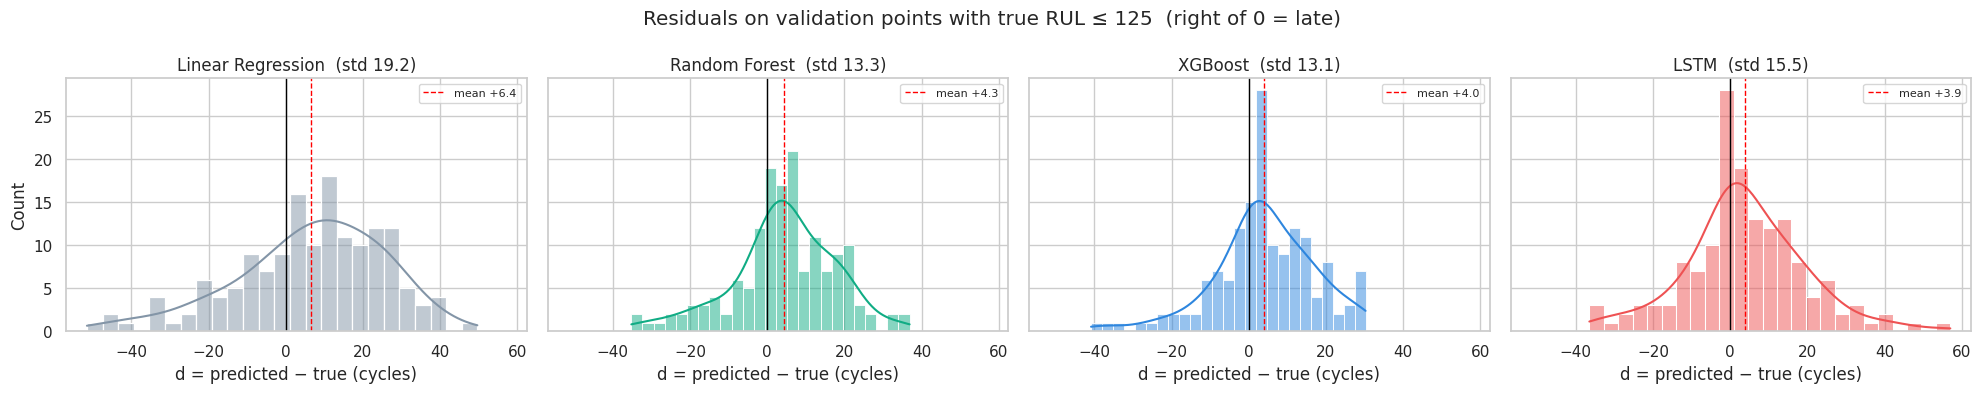

In [6]:
# Cell 5b — Residual distributions (true RUL ≤ 125)
mask = y_val <= CAP
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True, sharey=True)
for ax, name in zip(axes, MODELS):
    res = val_pred[name][mask] - y_val[mask]
    sns.histplot(res, bins=25, ax=ax, color=colors[name], kde=True)
    ax.axvline(0, color="black", lw=1)
    ax.axvline(res.mean(), color="red", ls="--", lw=1, label=f"mean {res.mean():+.1f}")
    ax.set(title=f"{name}  (std {res.std():.1f})", xlabel="d = predicted − true (cycles)")
    ax.legend(fontsize=8)
fig.suptitle("Residuals on validation points with true RUL ≤ 125  (right of 0 = late)")
fig.tight_layout(); fig.savefig(FIG_DIR / "18_residuals_val.png", dpi=150, bbox_inches="tight"); plt.show()

,n points,Linear Regression,Random Forest,XGBoost,LSTM
0–25,26,15.1,4.6,4.8,3.3
26–50,28,24.1,10.7,10.0,12.7
51–75,28,24.4,17.9,16.7,24.1
76–100,31,18.9,17.3,17.7,15.9
101–125,40,17.9,14.1,13.8,15.8
>125,47,78.2,73.8,73.8,76.6


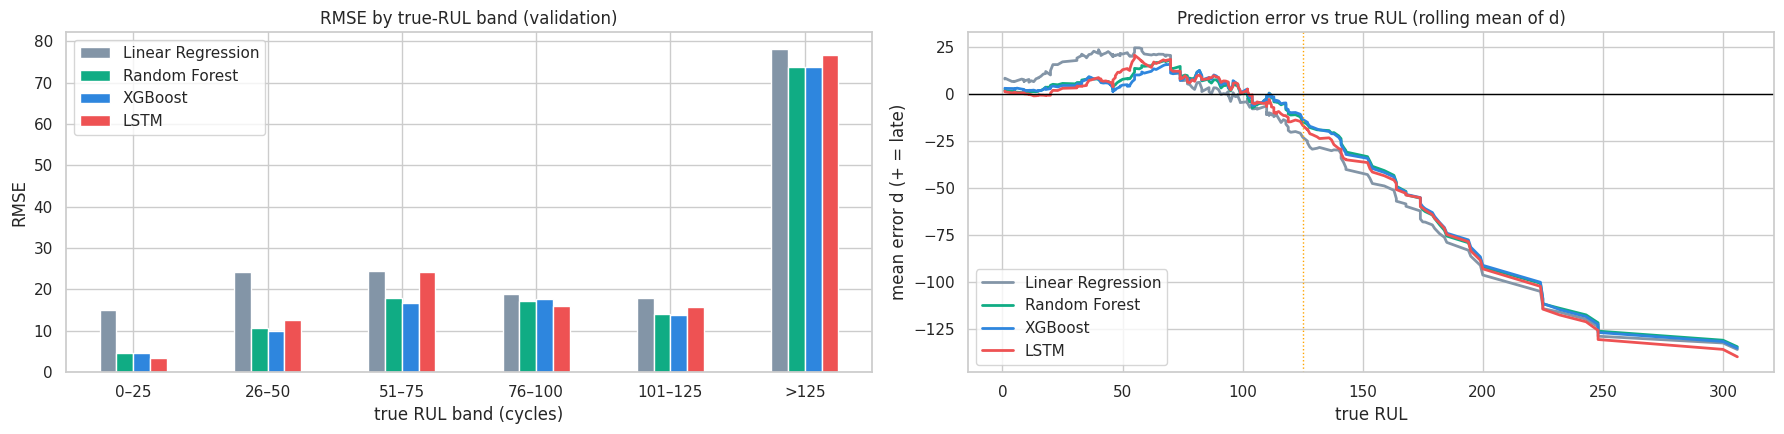

In [7]:
# Cell 5c — Error by RUL band + Cell 5d — error vs true RUL
bands = pd.cut(y_val, [-1, 25, 50, 75, 100, 125, 1000], labels=["0–25", "26–50", "51–75", "76–100", "101–125", ">125"])
band_tbl = pd.DataFrame({name: pd.Series(val_pred[name] - y_val).groupby(bands, observed=True)
                         .apply(lambda r: float(np.sqrt(np.mean(r ** 2)))) for name in MODELS})
band_tbl.insert(0, "n points", pd.Series(bands).value_counts().reindex(band_tbl.index).values)
band_tbl.to_csv(RESULT_DIR / "validation_rmse_by_band.csv")
display(band_tbl.round(1))

fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
band_tbl[MODELS].plot.bar(ax=axes[0], color=[colors[m] for m in MODELS], rot=0)
axes[0].set(title="RMSE by true-RUL band (validation)", xlabel="true RUL band (cycles)", ylabel="RMSE")
for name in MODELS:
    order = np.argsort(y_val)
    err = (val_pred[name] - y_val)[order]
    axes[1].plot(y_val[order], pd.Series(err).rolling(15, center=True, min_periods=5).mean(),
                 color=colors[name], label=name, lw=2)
axes[1].axhline(0, color="black", lw=1)
axes[1].axvline(CAP, color="orange", ls=":", lw=1)
axes[1].set(title="Prediction error vs true RUL (rolling mean of d)", xlabel="true RUL", ylabel="mean error d (+ = late)")
axes[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "19_error_by_band_val.png", dpi=150, bbox_inches="tight"); plt.show()

**What to expect in these plots (and why):**
- Above true RUL ≈ 125, every model's error turns strongly **negative** (early): the target was capped at 125, so a model can't predict 200 even when the truth is 200. This is the accepted trade-off from Phase 3 — such engines are "healthy, ≥125 cycles".
- In the **0–25** band (engines about to fail) errors should be smallest — degradation signals are strongest there. This is the band that matters most for safety.
- A positive (late) bump in the middle bands (≈ 50–110) is the most important thing to watch: that's where a model could tell a maintenance planner "plenty of life left" too optimistically.

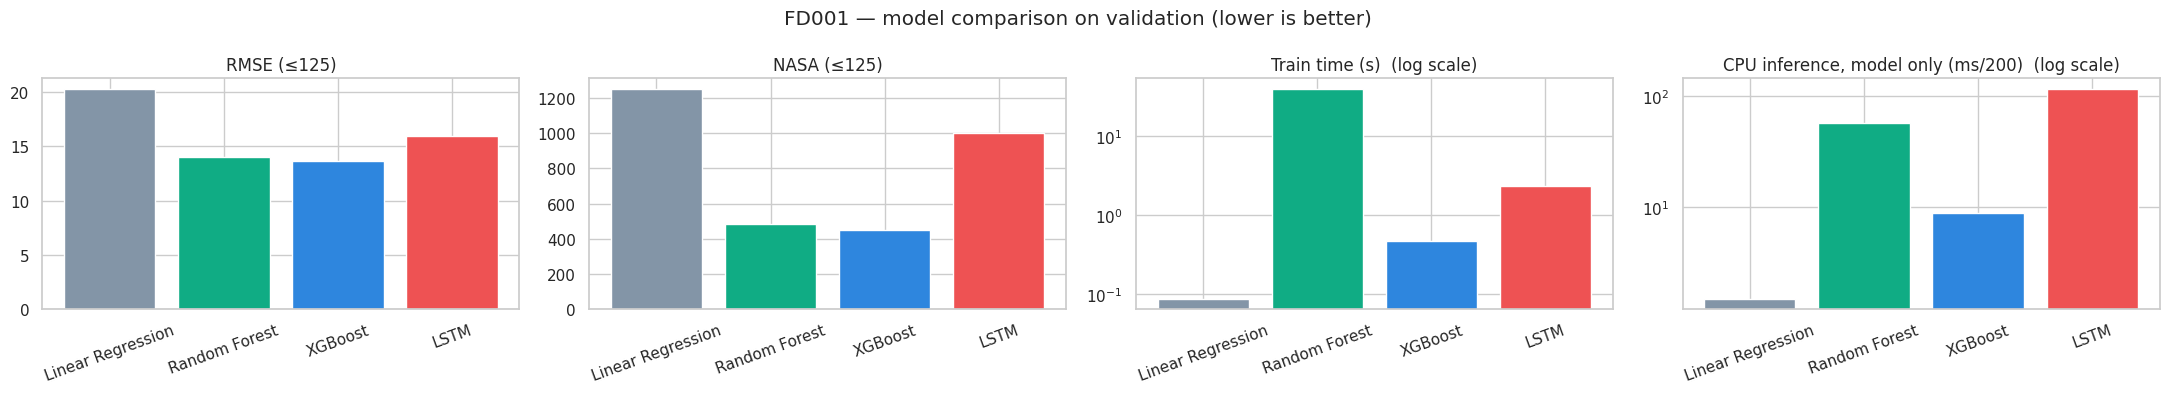

LSTM training curves (from Phase 5):


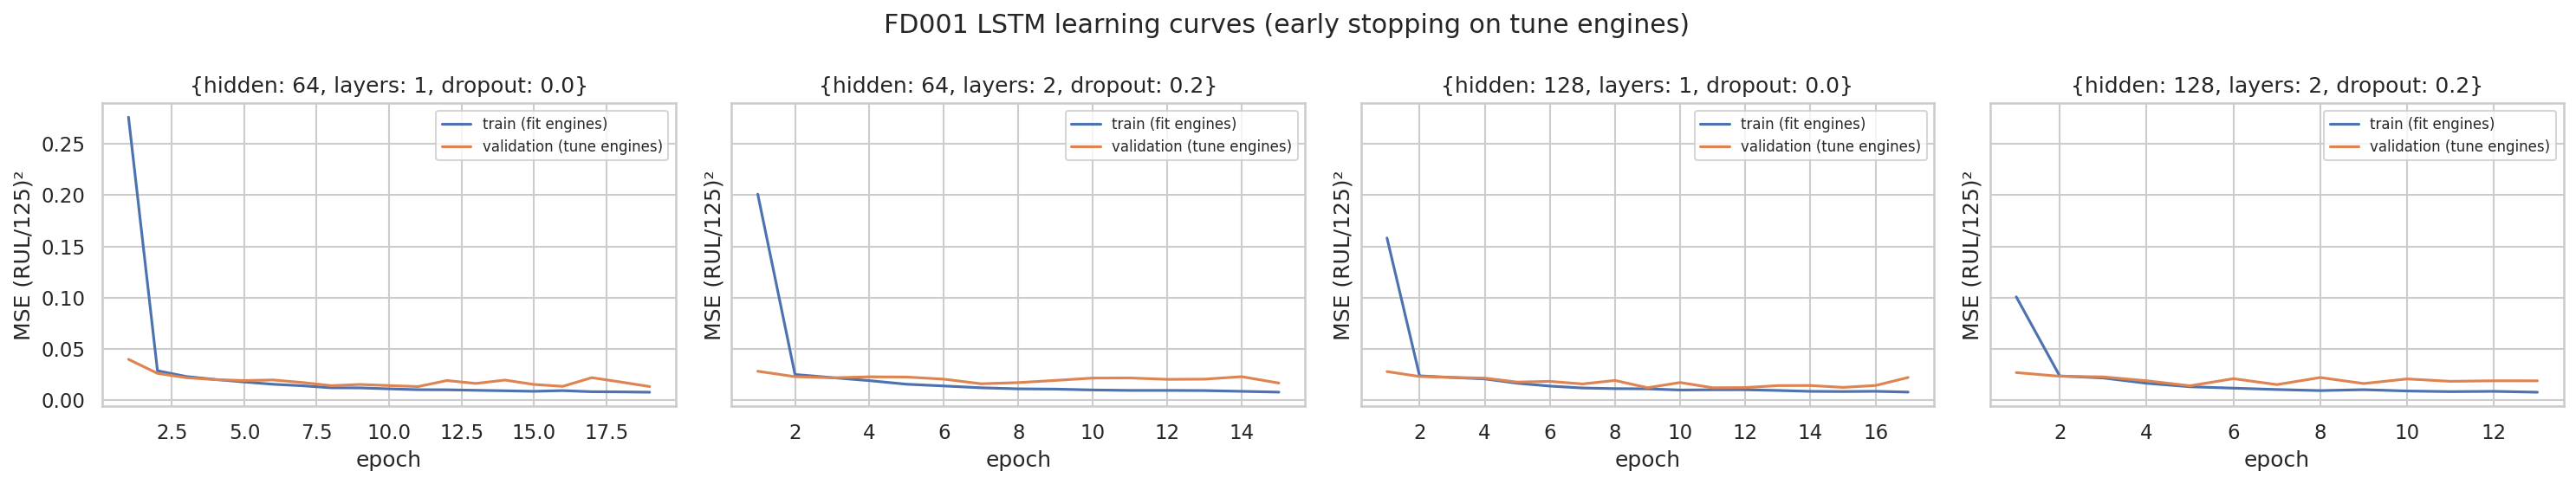

In [10]:
# Cell 5e — Model comparison bars + LSTM training curves from Phase 5
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, col, log in zip(axes, ["RMSE (≤125)", "NASA (≤125)", "Train time (s)", "CPU inference, model only (ms/200)"],
                        [False, False, True, True]):
    s = val_table[col]
    ax.bar(s.index, s.values, color=[colors[m] for m in s.index])
    ax.set(title=col + ("  (log scale)" if log else ""), yscale="log" if log else "linear")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("FD001 — model comparison on validation (lower is better)")
fig.tight_layout(); fig.savefig(FIG_DIR / "20_model_comparison_bars.png", dpi=150, bbox_inches="tight"); plt.show()

from IPython.display import Image, display as show
curves = FIG_DIR / "15_lstm_learning_curves.png"
if curves.exists():
    print("LSTM training curves (from Phase 5):"); show(Image(filename=str(curves), width=1100))

---
## Cell 6 — Select and FREEZE the production model (validation only)
**Selection rule (decided before looking at the test set):**
1. Rank by **validation RMSE on true RUL ≤ 125** (lower is better).
2. Any model within **0.5 RMSE** of the best is treated as a tie (with only 20 validation engines, smaller gaps are noise).
3. Among tied models, pick the lowest **NASA score** (fewer dangerous late errors).
4. If still tied: smaller model file, then faster CPU inference.

The choice is written to `models/FD001/selected_model.json`. **If that file already exists, it is NOT overwritten** — re-running this notebook can never change the selection after the test set has been seen.

In [11]:
# Cell 6 — Apply the rule and freeze
SEL_FILE = MODEL_DIR / "selected_model.json"
TIE_MARGIN = 0.5

ranked = val_table.sort_values("RMSE (≤125)")
best_rmse = ranked["RMSE (≤125)"].iloc[0]
tied = ranked[ranked["RMSE (≤125)"] <= best_rmse + TIE_MARGIN]
chosen = tied.sort_values(["NASA (≤125)", "Model size (MB)", "CPU inference, model only (ms/200)"]).index[0]
print("Ranking by validation RMSE (≤125):"); display(ranked[["RMSE (≤125)", "NASA (≤125)", "Bias (≤125)", "Model size (MB)"]].round(2))
print(f"Models within {TIE_MARGIN} of best ({best_rmse:.2f}): {list(tied.index)} → chosen by NASA score: {chosen}")

if SEL_FILE.exists():
    frozen = json.loads(SEL_FILE.read_text())
    print(f"\n🔒 Selection already frozen on {frozen['frozen_at_utc']}: {frozen['selected_model']} (not overwritten)")
    if frozen["selected_model"] != chosen:
        print("⚠️ The rule now gives a different answer — investigate, but the frozen choice stands.")
    SELECTED = frozen["selected_model"]
else:
    SELECTED = chosen
    SEL_FILE.write_text(json.dumps({
        "dataset": FD, "selected_model": SELECTED, "model_dir": pr.MODEL_FOLDERS[SELECTED],
        "rule": f"min validation RMSE(true RUL<=125); ties within {TIE_MARGIN} broken by NASA score, then size, then speed",
        "validation_metrics": {k: float(v) for k, v in val_table.loc[SELECTED].items()},
        "candidates": {m: {"RMSE_le125": float(val_table.loc[m, "RMSE (≤125)"]),
                           "NASA_le125": float(val_table.loc[m, "NASA (≤125)"])} for m in MODELS},
        "frozen_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "test_set_seen_before_selection": False}, indent=2))
    print(f"\n🔒 Frozen: {SELECTED} → {SEL_FILE}")

Ranking by validation RMSE (≤125):


,RMSE (≤125),NASA (≤125),Bias (≤125),Model size (MB)
Model,,,,
XGBoost,13.67,451.26,3.99,0.63
Random Forest,13.99,481.61,4.27,11.57
LSTM,15.95,1003.05,3.90,0.84
Linear Regression,20.26,1250.63,6.43,0.00


Models within 0.5 of best (13.67): ['XGBoost', 'Random Forest'] → chosen by NASA score: XGBoost

🔒 Selection already frozen on 2026-11-25T06:49:48+00:00: XGBoost (not overwritten)


---
## Cell 7 — Official NASA test evaluation (run once)
Now — and only now — we open `test_FD001.txt` and `RUL_FD001.txt`. For each of the 100 test engines the model sees its history up to the last observed cycle and predicts RUL; the RUL file gives the true answer.

- The **selected model's** score is the headline result.
- The other three are reported **for reference only** (the dashboard's comparison page needs them). They were **not** used for selection — Cell 6 already froze the choice.
- A record is saved to `test_evaluation.json`. If it already exists, the notebook warns you that the test set has been seen before.

In [12]:
# Cell 7 — Test evaluation
TEST_FILE = RESULT_DIR / "test_evaluation.json"
if TEST_FILE.exists():
    prev = json.loads(TEST_FILE.read_text())
    print(f"⚠️ Test set was already evaluated on {prev['evaluated_at_utc']}. Results are re-displayed only; "
          "do NOT change preprocessing/models/selection based on them.\n")

test_raw, rul_true = d["test"], d["rul"].set_index("engine_id")["true_rul"]
test_rows, test_preds = [], None
for name, p in predictors.items():
    out = p.predict_last(test_raw)
    y_t = rul_true.loc[out.engine_id].values
    yhat = out["predicted_rul"].values
    test_rows.append({"Model": name, "Selected": "★" if name == SELECTED else "",
                      "MAE": ev.mae(y_t, yhat), "RMSE": ev.rmse(y_t, yhat), "NASA score": ev.nasa_score(y_t, yhat),
                      "Bias": float(np.mean(yhat - y_t)),
                      "RMSE (true ≤125)": ev.rmse(y_t[y_t <= CAP], yhat[y_t <= CAP]),
                      "Late > 10 cycles (%)": float(np.mean(yhat - y_t > 10) * 100),
                      "Validation RMSE (≤125)": val_table.loc[name, "RMSE (≤125)"]})
    if test_preds is None:
        test_preds = out[["engine_id", "cut_cycle"]].assign(true_rul=y_t)
    test_preds[name] = yhat

test_table = pd.DataFrame(test_rows).set_index("Model")
test_table.to_csv(RESULT_DIR / "test_results.csv")
test_preds.to_csv(RESULT_DIR / "test_predictions.csv", index=False)
print(f"Official FD001 test set: {len(test_preds)} engines, true RUL {rul_true.min()}–{rul_true.max()}")
display(test_table.round(2))

if not TEST_FILE.exists():
    sel = test_table.loc[SELECTED]
    TEST_FILE.write_text(json.dumps({
        "dataset": FD, "selected_model": SELECTED, "n_engines": int(len(test_preds)),
        "selected_model_test_metrics": {k: float(sel[k]) for k in ["MAE", "RMSE", "NASA score", "Bias", "RMSE (true ≤125)"]},
        "reference_models_test_rmse": {m: float(test_table.loc[m, "RMSE"]) for m in MODELS},
        "evaluated_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "note": "Reference models were not used for selection; selection frozen in models/FD001/selected_model.json"}, indent=2))
    print("Saved →", TEST_FILE)

Official FD001 test set: 100 engines, true RUL 7–145


,Selected,MAE,RMSE,NASA score,Bias,RMSE (true ≤125),Late > 10 cycles (%),Validation RMSE (≤125)
Model,,,,,,,,
Linear Regression,,15.74,19.88,658.60,-0.35,18.07,30.0,20.26
Random Forest,,10.34,13.78,253.13,0.14,11.81,21.0,13.99
XGBoost,★,10.62,14.22,282.62,0.17,12.48,24.0,13.67
LSTM,,12.24,16.59,488.96,0.46,14.73,23.0,15.95


Saved → /content/drive/MyDrive/Predictive_Maintenance_RUL/reports/model_results/FD001/test_evaluation.json


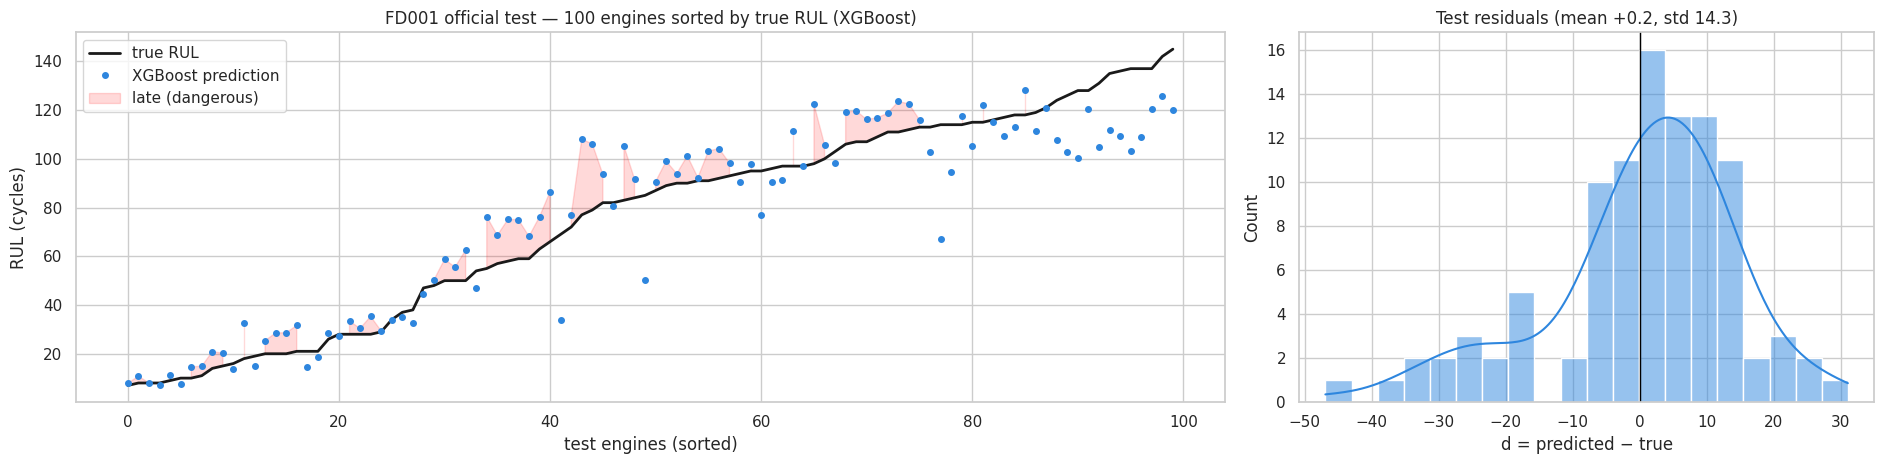

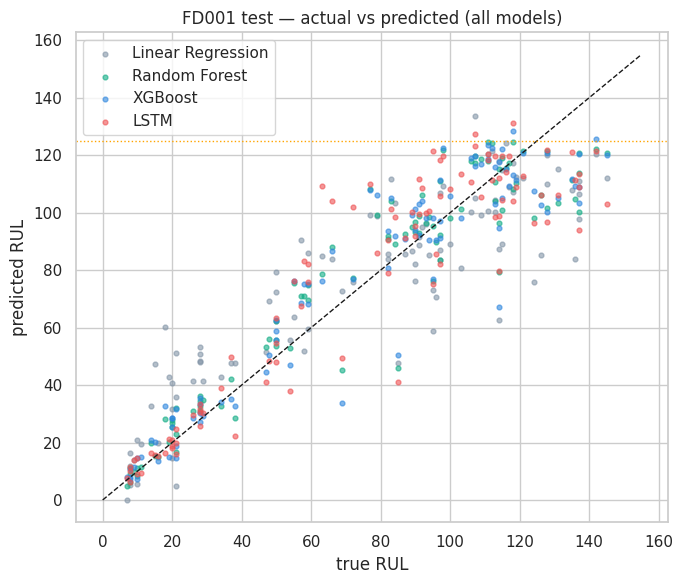

In [13]:
# Cell 7b — Test-set plots for the selected model
order = test_preds.sort_values("true_rul").reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(19, 4.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(order.index, order.true_rul, "k-", lw=2, label="true RUL")
axes[0].plot(order.index, order[SELECTED], "o", ms=4, color=colors[SELECTED], label=f"{SELECTED} prediction")
axes[0].fill_between(order.index, order.true_rul, order[SELECTED], where=order[SELECTED] > order.true_rul,
                     color="red", alpha=0.15, label="late (dangerous)")
axes[0].set(title=f"FD001 official test — 100 engines sorted by true RUL ({SELECTED})",
            xlabel="test engines (sorted)", ylabel="RUL (cycles)"); axes[0].legend()
res = order[SELECTED] - order.true_rul
sns.histplot(res, bins=20, kde=True, ax=axes[1], color=colors[SELECTED])
axes[1].axvline(0, color="black", lw=1)
axes[1].set(title=f"Test residuals (mean {res.mean():+.1f}, std {res.std():.1f})", xlabel="d = predicted − true")
fig.tight_layout(); fig.savefig(FIG_DIR / "21_test_selected_model.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name in MODELS:
    ax.scatter(test_preds.true_rul, test_preds[name], s=12, alpha=0.6, color=colors[name], label=name)
lim = test_preds.true_rul.max() + 10
ax.plot([0, lim], [0, lim], "k--", lw=1); ax.axhline(CAP, color="orange", ls=":", lw=1)
ax.set(title="FD001 test — actual vs predicted (all models)", xlabel="true RUL", ylabel="predicted RUL"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "22_test_actual_vs_predicted_all.png", dpi=150, bbox_inches="tight"); plt.show()

---
## Cell 8 — Summary

In [14]:
# Cell 8 — Summary
sel_val = val_table.loc[SELECTED]; sel_test = test_table.loc[SELECTED]
print(f"FD001 production model: {SELECTED}  (frozen in {SEL_FILE.name})")
print(f"  Validation (20 engines, 200 points, true RUL ≤ 125): RMSE {sel_val['RMSE (≤125)']:.2f} | MAE {sel_val['MAE (≤125)']:.2f}")
print(f"  Official test (100 engines, last cycle):             RMSE {sel_test['RMSE']:.2f} | MAE {sel_test['MAE']:.2f} | "
      f"NASA {sel_test['NASA score']:.0f} | bias {sel_test['Bias']:+.1f}")
print(f"  Test engines predicted > 10 cycles late: {sel_test['Late > 10 cycles (%)']:.0f}%")
print("\nArtifacts:", SEL_FILE.relative_to(PROJECT_DIR), "|", TEST_FILE.relative_to(PROJECT_DIR))
print("Results:  ", sorted(p.name for p in RESULT_DIR.iterdir()))

FD001 production model: XGBoost  (frozen in selected_model.json)
  Validation (20 engines, 200 points, true RUL ≤ 125): RMSE 13.67 | MAE 10.42
  Official test (100 engines, last cycle):             RMSE 14.22 | MAE 10.62 | NASA 283 | bias +0.2
  Test engines predicted > 10 cycles late: 24%

Artifacts: models/FD001/selected_model.json | reports/model_results/FD001/test_evaluation.json
Results:   ['lstm_tuning.csv', 'rf_feature_importance.csv', 'rf_tuning.csv', 'test_evaluation.json', 'test_predictions.csv', 'test_results.csv', 'validation_comparison.csv', 'validation_comparison_cpu.csv', 'validation_predictions.csv', 'validation_rmse_by_band.csv', 'xgb_feature_importance.csv', 'xgb_tuning.csv']


## Reference results (full test run of this notebook on a local CPU)
These come from models trained in a local CPU run of Phase 5. **Your Linear Regression and Random Forest numbers should match closely; your XGBoost and LSTM were trained on a GPU and will differ slightly** (your Phase 5 XGBoost validation RMSE was 13.67 vs 13.86 here).

**Selection (validation):** XGBoost 13.86 and Random Forest 13.99 are within 0.5 â†’ tie â†’ XGBoost wins on NASA score (468 vs 482). LSTM 15.41, Linear Regression 20.26.

**Official test (100 engines):**

| Model | MAE | RMSE | NASA score | Bias | Late > 10 cycles |
|---|---:|---:|---:|---:|---:|
| Linear Regression | 15.74 | 19.88 | 659 | âˆ’0.4 | 30% |
| Random Forest | 10.34 | 13.78 | 253 | +0.1 | 21% |
| **XGBoost â˜… (selected)** | **10.23** | **13.97** | **278** | **âˆ’0.0** | **20%** |
| LSTM | 11.97 | 16.16 | 771 | +3.1 | 25% |

Validation RMSE (13.86) and test RMSE (13.97) for the selected model are almost identical â†’ the validation protocol gave an honest estimate. Random Forest scoring marginally better on test is **within noise** and does **not** change the frozen selection â€” that is exactly the discipline this notebook enforces.